## In the Dijkstra’s algorithm, the choice of the input graph representation and the priority queue implementation will affect its time complexity.

In [2]:
import time
import random
import heapq
import matplotlib.pyplot as plt
import math

#### (a) Suppose the input graph G = (V, E) is stored in an adjacency matrix and we use an array for the priority queue. Implement the Dijkstra’s algorithm using this setting and analyze its time complexity with respect to |V| and |E| both theoretically and empirically.

In [41]:
def createGraph(V, E):
    adj_matrix = [[float("inf")] * V for _ in range(V)]
    maxEdges = V*(V-1)
    edges = min(maxEdges, E)
    i=0
    while i<edges:
        u1 = random.randint(0,V-1)
        u2 = random.randint(0,V-1)
        if u1 != u2 and adj_matrix[u1][u2] == float("inf"):
            edgeweight = random.randint(1,20)
            adj_matrix[u1][u2] = edgeweight
            i+=1
    return adj_matrix

def dijkstra_matrix(graph, src):
    V = len(graph)
    dist = [float("inf")] * V
    visited = [False] * V
    dist[src] = 0
    comparisons = 0

    for _ in range(V):
        u = -1
        for i in range(V):
            if not visited[i] and (u == -1 or dist[i] < dist[u]):
                u = i
            comparisons += 1

        visited[u] = True
        for v in range(V):
            if graph[u][v] != float("inf") and not visited[v]:
                comparisons += 1
                if dist[u] + graph[u][v] < dist[v]:
                    dist[v] = dist[u] + graph[u][v]
    return comparisons

Let’s break it down:

1. Outer loop runs V times → once for each vertex.

- First inner loop scans all V vertices to find the smallest unvisited one.
- → That’s 𝑂(𝑉)
- O(V) work per iteration.


2. Second inner loop 
- checks all V possible edges from u to other vertices, even if most don’t exist.
- → That’s another 𝑂(𝑉)
- O(V) work per iteration.

Total work ≈ 𝑂(𝑉)×(𝑂(𝑉)+𝑂(𝑉))=𝑂(𝑉^2)

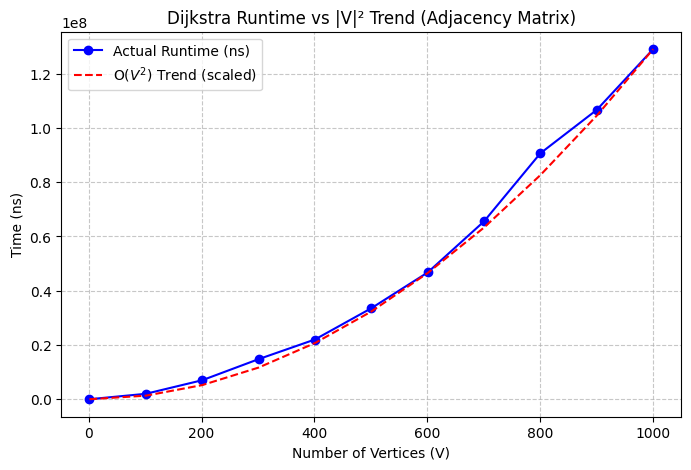

In [42]:
def test_performance():
    results = []
    for V in range(1, 1002, 100):
        E = 20000
        graph = createGraph(V, E)
        start = time.time_ns()
        comparisons = dijkstra_matrix(graph, 0)
        end = time.time_ns()
        results.append((V, E, comparisons, end - start))

    # Extract data
    Vs = [r[0] for r in results]
    times = [r[3] for r in results]

    # Normalize V^2 curve to similar scale as actual time
    v2_values = [v**2 for v in Vs]
    scale_factor = max(times) / max(v2_values)
    v2_scaled = [x * scale_factor for x in v2_values]

    # Plot runtime vs V and V² trendline
    plt.figure(figsize=(8,5))
    plt.plot(Vs, times, marker='o', linestyle='-', color='blue', label='Actual Runtime (ns)')
    plt.plot(Vs, v2_scaled, linestyle='--', color='red', label=r'O($V^2$) Trend (scaled)')
    plt.xlabel("Number of Vertices (V)")
    plt.ylabel("Time (ns)")
    plt.title("Dijkstra Runtime vs |V|² Trend (Adjacency Matrix)")
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

test_performance()


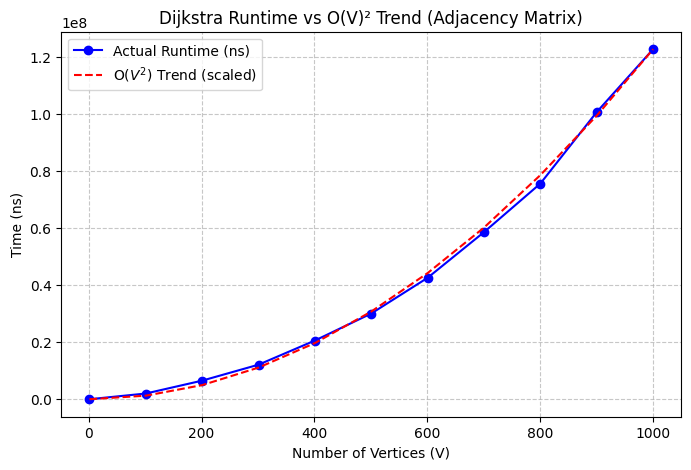

In [47]:
def test_performance():
    results = []
    for V in range(1, 1002, 100):
        E = 50
        graph = createGraph(V, E)
        start = time.time_ns()
        comparisons = dijkstra_matrix(graph, 0)
        end = time.time_ns()
        results.append((V, E, comparisons, end - start))

    # Extract data
    Vs = [r[0] for r in results]
    times = [r[3] for r in results]

    # Normalize V^2 curve to similar scale as actual time
    v2_values = [v**2 for v in Vs]
    scale_factor = max(times) / max(v2_values)
    v2_scaled = [x * scale_factor for x in v2_values]

    # Plot runtime vs V and V² trendline
    plt.figure(figsize=(8,5))
    plt.plot(Vs, times, marker='o', linestyle='-', color='blue', label='Actual Runtime (ns)')
    plt.plot(Vs, v2_scaled, linestyle='--', color='red', label=r'O($V^2$) Trend (scaled)')
    plt.xlabel("Number of Vertices (V)")
    plt.ylabel("Time (ns)")
    plt.title("Dijkstra Runtime vs O(V)² Trend (Adjacency Matrix)")
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

test_performance()

#### (b) Suppose the input graph G = (V, E) is stored in an array of adjacency lists and we use a minimizing heap for the priority queue. Implement the Dijkstra’s algorithm using this setting and analyze its time complexity with respect to |V| and |E| both theoretically and empirically.

In [3]:
def generate_graph(vertices, edges):
    graph = {i: [] for i in range(vertices)}
    max_edges = vertices * (vertices - 1)
    edges = min(edges, max_edges)
    added_edges = set()

    while len(added_edges) < edges:
        u = random.randint(0, vertices - 1)
        v = random.randint(0, vertices - 1)
        if u != v and (u, v) not in added_edges:
            weight = random.randint(1, 20)
            graph[u].append((v,weight))
            added_edges.add((u, v))
    return graph

# Dijkstra's algorithm using adjacency list and min-heap
def dijkstra(graph, src):
    vertices = len(graph)
    dist = [float('inf')] * vertices
    dist[src] = 0
    visited = [False] * vertices
    comparisons = 0

    heap = [(0, src)]  # (distance, vertex)

    while heap:
        current_dist, u = heapq.heappop(heap)
        if visited[u]:
            continue
        visited[u] = True

        for v, weight in graph[u]:
            comparisons += 1
            if not visited[v] and current_dist + weight < dist[v]:
                dist[v] = current_dist + weight
                heapq.heappush(heap, (dist[v], v))
    return comparisons


Let's break it down
1. logV
- We use min-heap/ priority queue to
- Extract the vertex with the smallest tentative distance and
- Update the distance of its neighbors if a shorter path is found.

2. V+E
- We do V extractions (each vertex once).
- We may do E relaxations (checking edges), and potentially E insertions or updates in the heap.

So, in total, we do **(V+E)** times of **logV** operations

Fixed E = 20000, Averaged over 5 runs per V
V,Avg_Time_ns


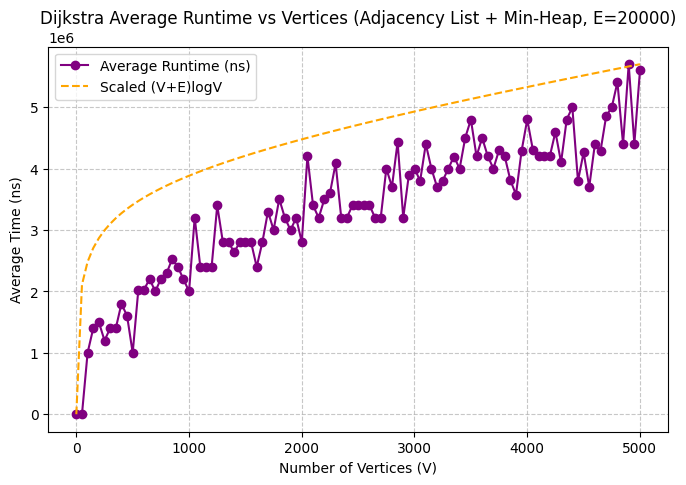

In [4]:
# Performance test: vary V, fix E, take average runtime
def test_vary_vertices_avg():
    E = 20000        # fixed number of edges
    runs = 5        # number of runs to average
    print(f"Fixed E = {E}, Averaged over {runs} runs per V")
    print("V,Avg_Time_ns")

    results = []
    for V in range(1, 5002, 50):  # vary number of vertices
        total_time = 0
        for _ in range(runs):
            graph = generate_graph(V, E)
            start = time.time_ns()
            dijkstra(graph, 0)
            end = time.time_ns()
            total_time += (end - start)
        avg_time = total_time / runs
        results.append((V, avg_time))

    # Extract results
    Vs = [r[0] for r in results]
    times = [r[1] for r in results]

    theoretical = [(v + E) * math.log(v) for v in Vs]
    scale_factor = max(times) / max(theoretical)  # normalize to match magnitude
    theoretical_scaled = [t * scale_factor for t in theoretical]

    # Plot runtime vs vertices
    plt.figure(figsize=(8,5))
    plt.plot(Vs, times, marker='o', linestyle='-', color='purple', label='Average Runtime (ns)')
    plt.plot(Vs, theoretical_scaled, linestyle='--', color='orange', label='Scaled (V+E)logV')
    plt.xlabel("Number of Vertices (V)")
    plt.ylabel("Average Time (ns)")
    plt.title(f"Dijkstra Average Runtime vs Vertices (Adjacency List + Min-Heap, E={E})")
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

test_vary_vertices_avg()

Fixed V = 5000, Averaged over 5 runs per E
V,Avg_Time_ns


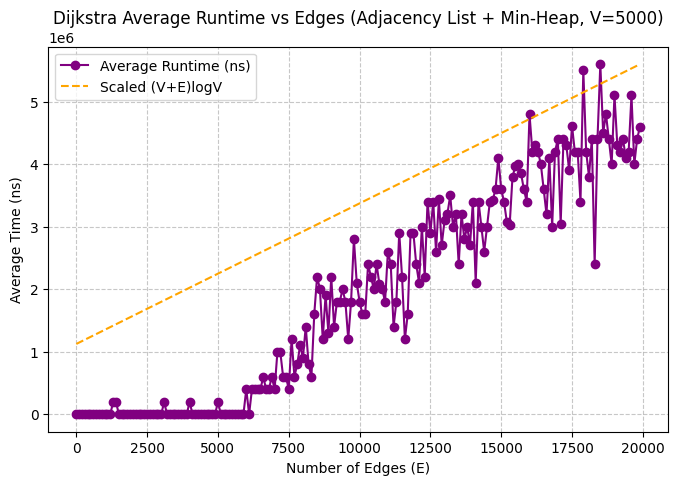

In [ ]:
# Performance test: vary E, fix V, take average runtime
def test_vary_edges_avg():
    V = 200        # fixed number of vertices
    runs = 5        # number of runs to average
    print(f"Fixed V = {V}, Averaged over {runs} runs per E")
    print("V,Avg_Time_ns")

    results = []
    for E in range(1, 20000, 50):  # vary number of vertices
        total_time = 0
        for _ in range(runs):
            graph = generate_graph(V, E)
            start = time.time_ns()
            dijkstra(graph, 0)
            end = time.time_ns()
            total_time += (end - start)
        avg_time = total_time / runs
        results.append((E, avg_time))

    # Extract results
    Es = [r[0] for r in results]
    times = [r[1] for r in results]

    theoretical = [(V + e) * math.log(V) for e in Es]
    scale_factor = max(times) / max(theoretical)  # normalize to match magnitude
    theoretical_scaled = [t * scale_factor for t in theoretical]

    # Plot runtime vs vertices
    plt.figure(figsize=(8,5))
    plt.plot(Es, times, marker='o', linestyle='-', color='purple', label='Average Runtime (ns)')
    plt.plot(Es, theoretical_scaled, linestyle='--', color='orange', label='Scaled (V+E)logV')
    plt.xlabel("Number of Edges (E)")
    plt.ylabel("Average Time (ns)")
    plt.title(f"Dijkstra Average Runtime vs Edges (Adjacency List + Min-Heap, V={V})")
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.legend()
    plt.show()

test_vary_edges_avg()

#### (c) Compare the two implementations in (a) and (b). Discuss which implementation is better and in what circumstances.